# Getting started with parametric priors

In this tutorial, we learn a prior for a linear regression from expert knowledge.
The expert does not state the prior.
The expert states what they expect to observe.
`elicito` finds the prior that reproduces these expectations.

We go through five steps:

1. Write the generative model.
2. Give each model parameter a prior family with hyperparameters.
3. Define the target quantities that we ask the expert about.
4. Learn the hyperparameters with CMA-ES.
5. Check the result with the diagnostic plots.

In [1]:
import os

os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"

import joblib


def _warm() -> None:
    import elicito  # noqa: F401


joblib.Parallel(n_jobs=4)(joblib.delayed(_warm)() for _ in range(4))

import tensorflow as tf

tf.constant(0.0)

<tf.Tensor: shape=(), dtype=float32, numpy=0.0>

## Imports

In [2]:
from functools import partial
from typing import Any

import numpy as np
import tensorflow as tf
import tensorflow_probability as tfp

import elicito as el

tfd = tfp.distributions

## The model

### Probabilistic model

We use a linear regression with one predictor $X$:

$$
\begin{align*}
    \beta_0 &\sim \text{Normal}(\mu_0, \sigma_0) \\
    \beta_1 &\sim \text{Normal}(\mu_1, \sigma_1) \\
    \sigma &\sim \text{HalfNormal}(\sigma_2) \\
    \mu &= \beta_0 + \beta_1 X \\
    y_{pred} &\sim \text{Normal}(\mu, \sigma)
\end{align*}
$$

### Design matrix

The predictor takes the values $0, 1, \dots, N-1$. We divide it by its
standard deviation. We then ask the expert about the outcome at three
values of the predictor: its 25th ($X_0$), 50th ($X_1$) and 75th ($X_2$)
percentile.

In [3]:
def X_design(N: int, quantiles: list[float]) -> Any:
    """
    Compute the design matrix

    Parameters
    ----------
    N
        number of observations

    quantiles
        percentiles of the scaled predictor, from 0 to 100

    Returns
    -------
    :
        design matrix with one row per percentile
    """
    X = tf.cast(np.arange(N), tf.float32)
    X_scaled = X / tf.math.reduce_std(X)
    X_sel = tfp.stats.percentile(X_scaled, quantiles)
    design = tf.stack([tf.ones(X_sel.shape), X_sel], -1)
    return design


X_design(N=30, quantiles=[25, 50, 75])

<tf.Tensor: shape=(3, 2), dtype=float32, numpy=
array([[1.        , 0.80873984],
       [1.        , 1.6174797 ],
       [1.        , 2.5417538 ]], dtype=float32)>

### Generative model

The generative model is a class with a `__call__` method. It receives the
prior samples and the design matrix. It returns a dictionary with every
quantity that a target can use.
Bind every argument other than `prior_samples` with `functools.partial`.

The prior samples have the shape `(B, num_samples, number of parameters)`.
The last column is $\sigma$. The other columns are the regression
coefficients.

In [4]:
class ToyModel:
    """
    Generative model of the linear regression
    """

    def __call__(self, prior_samples: Any, design_matrix: Any) -> dict[str, Any]:
        """
        Compute the target quantities from the generative model

        Parameters
        ----------
        prior_samples
            prior samples

        design_matrix
            design matrix

        Returns
        -------
        :
            dictionary with the target quantities
        """
        # linear predictor
        epred = tf.matmul(prior_samples[:, :, :-1], design_matrix, transpose_b=True)

        # data-generating model
        likelihood = tfd.Normal(
            loc=epred, scale=tf.expand_dims(prior_samples[:, :, -1], -1)
        )
        # prior predictive distribution
        ypred = likelihood.sample()

        # outcome at the three selected predictor values
        y_X0, y_X1, y_X2 = (ypred[:, :, 0], ypred[:, :, 1], ypred[:, :, 2])

        return dict(y_X0=y_X0, y_X1=y_X1, y_X2=y_X2, ypred=ypred, epred=epred)

In [5]:
model = partial(ToyModel(), design_matrix=X_design(N=30, quantiles=[25, 50, 75]))

## Model parameters

Each model parameter gets a prior family. Each hyperparameter of that
family is a value that `elicito` learns.

| parameter | prior family | hyperparameters | constraint |
| :-- | :-- | :-- | :-- |
| intercept $\beta_0$ | Normal | $\mu_0$, $\sigma_0$ | $\sigma_0 > 0$ |
| slope $\beta_1$ | Normal | $\mu_1$, $\sigma_1$ | $\sigma_1 > 0$ |
| noise $\sigma$ | HalfNormal | $\sigma_2$ | $\sigma_2 > 0$ |

`lower=0` constrains a scale hyperparameter to positive values.

In [6]:
parameters = [
    el.parameter(
        name="beta0",
        family=tfd.Normal,
        hyperparams=dict(loc=el.hyper("mu0"), scale=el.hyper("sigma0", lower=0)),
    ),
    el.parameter(
        name="beta1",
        family=tfd.Normal,
        hyperparams=dict(loc=el.hyper("mu1"), scale=el.hyper("sigma1", lower=0)),
    ),
    el.parameter(
        name="sigma",
        family=tfd.HalfNormal,
        hyperparams=dict(scale=el.hyper("sigma2", lower=0)),
    ),
]

# titles for the plots, in the order of the hyperparameters above
TITLES = [r"$\mu_0$", r"$\sigma_0$", r"$\mu_1$", r"$\sigma_1$", r"$\sigma_2$"]

## Target quantities and elicitation techniques

A **target quantity** is a quantity that the expert can judge. The
**elicitation technique** is the question that we ask the expert about it.

| target quantity | elicitation technique | discrepancy measure | weight |
| :-- | :-- | :-- | --: |
| $y \mid X_0$, $y \mid X_1$, $y \mid X_2$ | quantiles $Q_p$, $p = 5, 25, 50, 75, 95$ | MMD² with energy kernel | 1.0 |
| $R^2$ | quantiles $Q_p$, $p = 5, 50, 95$ | L2 loss | 0.5 |

The model does not return $R^2$. The function `custom_r2` computes it from
the model output. `elicito` matches its arguments to the keys of the model
output by name.

In [7]:
def custom_r2(ypred: Any, epred: Any) -> Any:
    """Compute the coefficient of determination"""
    var_epred = tf.math.reduce_variance(epred, -1)
    # variance of the difference between ypred and epred
    var_diff = tf.math.reduce_variance(tf.subtract(ypred, epred), -1)
    var_total = var_epred + var_diff
    # variance of the linear predictor divided by the total variance
    return tf.divide(var_epred, var_total)


PROBS = (0.05, 0.25, 0.50, 0.75, 0.95)

targets = [
    el.quantiles("y_X0", probs=PROBS),
    el.quantiles("y_X1", probs=PROBS),
    el.quantiles("y_X2", probs=PROBS),
    el.quantiles("R2", output=custom_r2, loss=el.losses.L2, weight=0.5),
]

## Expert elicitation

We do not ask a real expert. We define a ground truth, the **oracle**, and
simulate the answers that the oracle gives. Because we know the true
prior, we can later see whether `elicito` recovers it.

In [8]:
ground_truth = {
    "beta0": tfd.Normal(loc=5, scale=1),
    "beta1": tfd.Normal(loc=2, scale=1),
    "sigma": tfd.HalfNormal(scale=7.0),
}

expert = el.expert.simulator(ground_truth=ground_truth, num_samples=10_000)

## Training

We learn the hyperparameters with **CMA-ES**, the default for a parametric prior.
We give three settings:

- `seeds` runs one replication for each seed, in parallel.
  The replications show if the result depends on the seed.
- `epochs` is the budget in forward simulations.
  The loss curve has one point per CMA-ES generation.
- `kappa` keeps a prior from collapsing to a point mass.

[`Elicit`][elicito.elicit.Elicit] lists all settings.

In [9]:
eliobj = el.Elicit(
    model, targets, parameters, seeds=(2025, 2026, 2027, 2028), epochs=800, kappa=0.1
)

Print the `eliobj` to see a summary of the settings.

In [10]:
eliobj

Model hyperparameters: 5
Model parameters: 3
Targets -> Elicited summaries (loss components): 4
  - y_X0 (128, 200) -> quantiles (128, 5)
  - y_X1 (128, 200) -> quantiles (128, 5)
  - y_X2 (128, 200) -> quantiles (128, 5)
  - R2 (128, 200) -> quantiles (128, 3)
Prior samples: 200 (128, 200, 3)
Batch size: 128
Epochs: 800
Method: parametric_prior
Seed: 2025
Optimizer: cmaes(sigma0=0.5)
Initializer: (method: SamplingMethod.cmaes, iterations: 500)

In [11]:
fit = eliobj.fit(expert)

Output()

`fit()` returns a `Fit` object. Print it to see a summary of the result.

In [12]:
fit

Method: parametric_prior (800 epochs)
Shown: replication [2] (best)

Hyperparameters:
         estimate     rep_sd        min        max
mu0          4.82      0.172       4.82       5.22
mu1             2     0.0813       1.85       2.03
sigma0       1.13      0.566       1.04       2.14
sigma1       1.08      0.241      0.921       1.43
sigma2       6.93      0.197       6.48       6.93

Priors:
            mean         sd        q05        q95
beta0       4.81       1.12       2.99       6.66
beta1          2       1.08      0.214       3.78
sigma       5.57       4.16       0.44       13.6

Fit to expert:
            expert   elicited      error
y_X0[0]      -4.85      -4.61      0.242
y_X0[1]       3.73       3.59     -0.136
y_X0[2]       6.56       6.48    -0.0796
y_X0[3]       9.44       9.34     -0.106
y_X0[4]       17.9       17.5     -0.376
y_X1[0]      -3.17      -3.07     0.0971
y_X1[1]       5.07       4.81      -0.26
y_X1[2]       8.19       8.06     -0.133
y_X1[3]       

## Results

### Convergence of the loss

The loss must decrease and then stay flat. Each line is one replication.

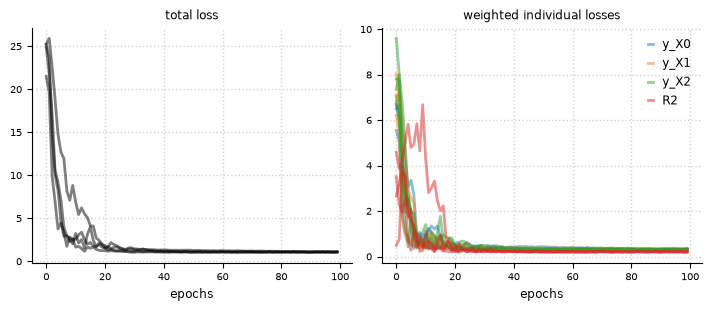

In [13]:
fit.plot.loss(figsize=(7, 3));

### Convergence of the hyperparameters

Each hyperparameter must settle on one value. When the replications settle
on the same value, the result does not depend on the seed.

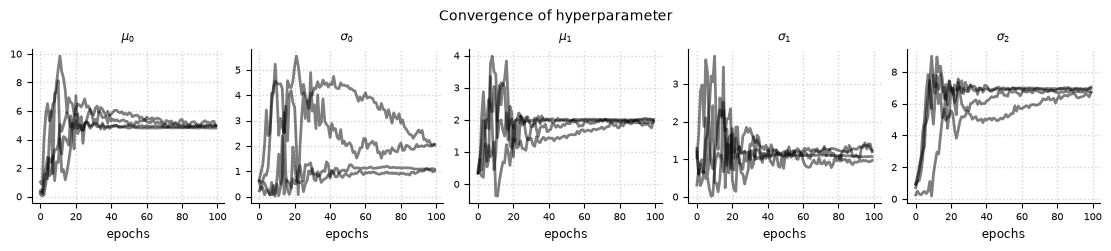

In [14]:
fit.plot.hyperparameter(titles=TITLES, cols=5, figsize=(11, 2.4));

### Expert expectations

Each point compares one elicited quantile of the expert with the same
quantile of the learned model. The points lie on the diagonal when the
learned prior reproduces the expert data.

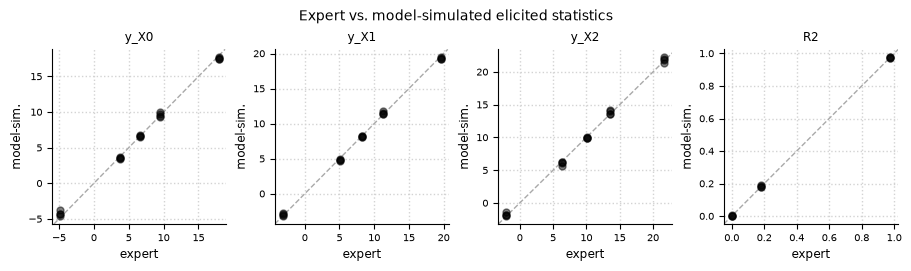

In [15]:
fit.plot.elicits(cols=4, figsize=(9, 2.6));

### Learned prior distributions

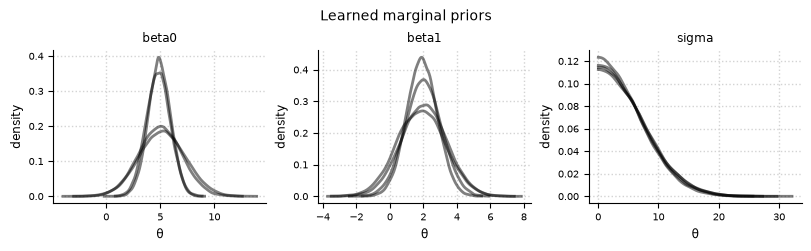

In [16]:
fit.plot.prior_marginals(cols=3, figsize=(8, 2.4));

### Prior predictive distribution of $R^2$

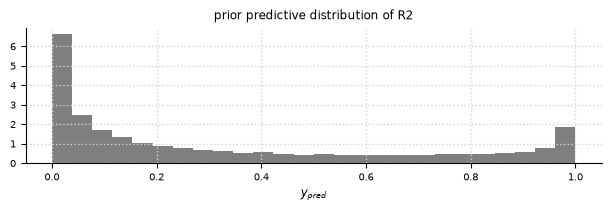

In [17]:
fit.plot.priorpredictive(target="R2");

### Averaged prior over the replications

The four replications give four priors. The plot averages them. The
weight of a replication comes from its mean loss over the last 30 history
points.

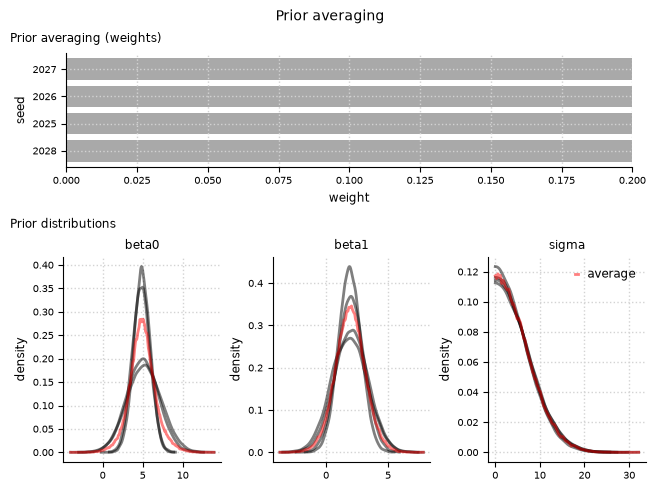

In [18]:
fit.plot.prior_averaging();

## Use the answers of a real expert

A real expert gives the answers as numbers.
Give them to `fit()` as a dictionary.
The key of each answer is the name of its target.

In [19]:
expert_dat = {
    "y_X0": [-12.5, -0.6, 3.3, 7.1, 19.1],
    "y_X1": [-11.2, 1.5, 5.0, 8.8, 20.4],
    "y_X2": [-9.3, 3.1, 6.8, 10.5, 23.3],
    "R2": [0.001, 0.09, 0.96],
}

eliobj_dat = el.Elicit(
    model, targets, parameters, seeds=(2025,), epochs=800, verbose=False
)

fit_dat = eliobj_dat.fit(expert_dat)

Check that the learned prior reproduces the answers.

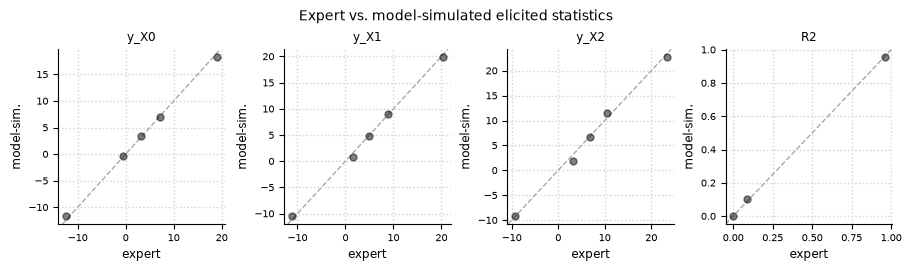

In [20]:
fit_dat.plot.elicits(cols=4, figsize=(9, 2.6));

## Next steps

We learned a parametric prior from the answers of one expert.
We checked it with the diagnostic plots.

- [Getting started with a non-parametric joint prior][getting-started-with-a-non-parametric-joint-prior] learns a prior without a prior family.
- [A hierarchical prior for a panel of experts][a-hierarchical-prior-for-a-panel-of-experts] combines the answers of several experts.
- The [how-to guides][how-to-guides] solve one task each, for example a PyMC model.